# 11 — Evaluating every model from many directions

One notebook, one protocol, every model. The same five subject folds and the same validation subjects as notebooks 07 to 09,
so all models are tested on identical unseen people. Models are read from the saved embeddings on Drive
(a simple probe on top of each frozen model) plus the saved EEGNet outputs. Whatever is missing is skipped.

**The directions**
1. **Accuracy,** with a 95% interval from resampling subjects (not trials, since trials of one person are not independent).
2. **Chance, measured instead of assumed:** labels shuffled inside each person, the whole pipeline rerun, and the real accuracy compared
   with that spread (a permutation test).
3. **A second protocol:** leave one subject out (31 folds) against the five folds. If the two disagree, the result depends on the split.
4. **Many metrics:** AUC, log loss, Brier score, and calibration error with two binning schemes.
5. **Confidence:** temperature scaling before and after, and accuracy when only the most confident trials are answered.
6. **Pretraining effect:** each pretrained model beside its random-weight copy.
7. **Subject identity:** how well the embeddings identify WHICH PERSON a trial came from (chance is 1 in 31).
8. **Person-level centering:** the same probe after removing each person's mean embedding (label-free, but it uses the new person's trials,
   so it is flagged).
9. **Pairwise tests:** paired Wilcoxon tests on per-subject accuracy, with Holm correction.

The probe's one setting (regularization strength) is chosen on validation subjects only. Test subjects are never used to choose anything.

## 1. Mount Drive and load every embedding that exists

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from scipy.special import expit
from scipy.optimize import minimize_scalar
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, StratifiedKFold

DATA_DIR = "/content/drive/MyDrive/eeg_data_cache/processed"
RESULT_DIR = "/content/drive/MyDrive/eeg_data_cache/results"
EMB = f"{DATA_DIR}/embeddings"
TAGS = ["vit", "labram", "labram59", "labram14", "labram59_random", "labram14_random"]
NOTES = {"vit": "ViT-B/16, channel C3 only", "labram": "LaBraM, 62 channels incl. 2 broken (first look)", "labram59": "LaBraM, 59 channels",
         "labram14": "LaBraM, 14 motor electrodes", "labram59_random": "random-weight LaBraM, 59 channels", "labram14_random": "random-weight LaBraM, 14 electrodes"}

def exists(t): return all(os.path.exists(f"{EMB}/{t}_guttmannflury2025_mi_subject{s}.npz") for s in range(1, 32))
AVAILABLE = [t for t in TAGS if exists(t)]
print("found:", AVAILABLE, "| missing:", [t for t in TAGS if t not in AVAILABLE])

DATA, y, groups = {}, None, None
for t in AVAILABLE:
    Xs, ys, gs = [], [], []
    for s in range(1, 32):
        d = np.load(f"{EMB}/{t}_guttmannflury2025_mi_subject{s}.npz")
        Xs.append(d["embeddings"]); ys.append((d["labels"] == 2).astype(int)); gs.append(np.full(len(d["labels"]), s))
    DATA[t] = np.concatenate(Xs); yt, gt = np.concatenate(ys), np.concatenate(gs)
    if y is None: y, groups = yt, gt
    assert (yt == y).all() and (gt == groups).all(), f"{t}: trial order differs from the others"
    print(f"{t:16} {DATA[t].shape}  {NOTES[t]}")
print("trials:", len(y), "| subjects:", len(np.unique(groups)), "| right-hand share:", round(float(y.mean()), 3))

Mounted at /content/drive
found: ['vit', 'labram', 'labram59', 'labram14', 'labram59_random', 'labram14_random'] | missing: []
vit              (1240, 768)  ViT-B/16, channel C3 only
labram           (1240, 200)  LaBraM, 62 channels incl. 2 broken (first look)
labram59         (1240, 200)  LaBraM, 59 channels
labram14         (1240, 200)  LaBraM, 14 motor electrodes
labram59_random  (1240, 200)  random-weight LaBraM, 59 channels
labram14_random  (1240, 200)  random-weight LaBraM, 14 electrodes
trials: 1240 | subjects: 31 | right-hand share: 0.5


## 2. The same folds and validation subjects as the earlier notebooks

In [2]:
FOLDS = []
for fold, (tr, te) in enumerate(GroupKFold(n_splits=5).split(y, y, groups)):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=fold)
    fit_i, val_i = next(gss.split(tr, y[tr], groups[tr]))
    FOLDS.append((tr[fit_i], tr[val_i], te))
    assert not set(groups[te]) & set(groups[tr])
    print(f"Fold {fold}: held-out subjects {[int(s) for s in sorted(set(groups[te]))]}")

Fold 0: held-out subjects [1, 6, 11, 16, 21, 26, 31]
Fold 1: held-out subjects [5, 10, 15, 20, 25, 30]
Fold 2: held-out subjects [4, 9, 14, 19, 24, 29]
Fold 3: held-out subjects [3, 8, 13, 18, 23, 28]
Fold 4: held-out subjects [2, 7, 12, 17, 22, 27]


## 3. Metrics and the probe

The probe is a logistic regression on the frozen embedding. Its regularization strength C is chosen per fold on validation subjects
by log loss, then the temperature is fitted on the same validation subjects.

In [3]:
def ece_equal(p1, yt, n_bins=10):
    conf = np.maximum(p1, 1 - p1); correct = ((p1 >= 0.5).astype(int) == yt).astype(float)
    edges = np.linspace(0.5, 1.0, n_bins + 1); edges[-1] = 1.0 + 1e-9; ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf >= lo) & (conf < hi)
        if m.sum(): ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)

def ece_adaptive(p1, yt, n_bins=10):                       # bins with equal numbers of trials
    conf = np.maximum(p1, 1 - p1); correct = ((p1 >= 0.5).astype(int) == yt).astype(float)
    return float(sum(len(c) / len(yt) * abs(correct[c].mean() - conf[c].mean()) for c in np.array_split(np.argsort(conf), n_bins) if len(c)))

def logloss(p1, yt):
    p = np.clip(p1, 1e-7, 1 - 1e-7); return float(-np.mean(yt * np.log(p) + (1 - yt) * np.log(1 - p)))

def brier(p1, yt): return float(np.mean((p1 - yt) ** 2))

def fit_temperature(z, yt):
    return float(minimize_scalar(lambda T: logloss(expit(z / T), yt), bounds=(0.05, 20.0), method="bounded").x)

def acc_at_coverage(p1, yt, cov=0.2):
    conf = np.maximum(p1, 1 - p1); correct = ((p1 >= 0.5).astype(int) == yt)
    return float(correct[np.argsort(-conf)[:max(1, int(round(cov * len(yt))))]].mean())

CS = [0.001, 0.01, 0.1, 1.0]

def center_by_subject(X):                                  # label-free: subtract each person's own mean
    Xc = X.copy()
    for s in range(1, 32): Xc[groups == s] -= Xc[groups == s].mean(0)
    return Xc

def run_probe(X, center=False):
    X = center_by_subject(X) if center else X
    z_raw, z_ts, temps, chosen = np.zeros(len(y)), np.zeros(len(y)), [], []
    for fold, (fit_idx, val_idx, te) in enumerate(FOLDS):
        sc = StandardScaler().fit(X[fit_idx]); Xf, Xv, Xt = sc.transform(X[fit_idx]), sc.transform(X[val_idx]), sc.transform(X[te])
        best = None
        for C in CS:
            clf = LogisticRegression(C=C, max_iter=3000).fit(Xf, y[fit_idx])
            zv = clf.decision_function(Xv); ll = logloss(expit(zv), y[val_idx])
            if best is None or ll < best[0]: best = (ll, C, clf, zv)
        _, C, clf, zv = best
        T = fit_temperature(zv, y[val_idx]); zt = clf.decision_function(Xt)
        z_raw[te], z_ts[te] = zt, zt / T; temps.append(T); chosen.append(C)
    return dict(z_raw=z_raw, z_ts=z_ts, temps=temps, Cs=chosen)

def per_subject_acc(z): return np.array([((z[groups == s] >= 0).astype(int) == y[groups == s]).mean() for s in range(1, 32)])

## 4. Run the probe on every embedding, and load the saved EEGNet outputs

`center` is the person-level centering direction (label-free, flagged). EEGNet needs no probe, so its saved scores are used directly.

In [4]:
RES, CENTERED = {}, {}
for t in AVAILABLE:
    RES[t] = run_probe(DATA[t])
    CENTERED[t] = run_probe(DATA[t], center=True)
    a, c = ((RES[t]["z_raw"] >= 0).astype(int) == y).mean(), ((CENTERED[t]["z_raw"] >= 0).astype(int) == y).mean()
    print(f"{t:16} accuracy {a:.3f} | chosen C per fold {RES[t]['Cs']} | with person-level centering {c:.3f}")

EEGNET = {"eegnet_all59": f"{RESULT_DIR}/eegnet_all_v3_fold_outputs.npz", "eegnet14_v2": f"{RESULT_DIR}/eegnet14_v2_fold_outputs.npz"}
for name, path in EEGNET.items():
    if os.path.exists(path):
        o = np.load(path)
        assert (o["y"] == y).all(), f"{name}: trial order differs"
        RES[name] = dict(z_raw=o["logits_raw"], z_ts=o["logits_ts"], temps=list(o["temps"]), Cs=None)
        print(f"{name:16} loaded from Drive, accuracy {((o['logits_raw'] >= 0).astype(int) == y).mean():.3f}")
NAMES = list(RES)

vit              accuracy 0.520 | chosen C per fold [0.001, 0.001, 0.001, 0.001, 0.001] | with person-level centering 0.519
labram           accuracy 0.564 | chosen C per fold [0.001, 0.01, 0.01, 0.01, 0.001] | with person-level centering 0.570
labram59         accuracy 0.529 | chosen C per fold [0.001, 0.01, 0.001, 0.001, 0.001] | with person-level centering 0.517
labram14         accuracy 0.531 | chosen C per fold [0.001, 0.01, 0.001, 0.001, 0.001] | with person-level centering 0.550
labram59_random  accuracy 0.501 | chosen C per fold [0.001, 0.001, 0.001, 0.001, 0.001] | with person-level centering 0.486
labram14_random  accuracy 0.496 | chosen C per fold [0.001, 0.001, 0.001, 0.001, 0.001] | with person-level centering 0.508
eegnet_all59     loaded from Drive, accuracy 0.599
eegnet14_v2      loaded from Drive, accuracy 0.555


## 5. Accuracy with an interval, and measured chance (permutation test)

The interval resamples subjects. The permutation test shuffles labels inside every person, reruns the whole pipeline
(same folds, same C), and asks how often shuffled labels reach the real accuracy. Set `N_PERM` higher for a finer p-value (100 gives the smallest possible p of about 0.01).

In [5]:
N_PERM = 100
rng_b = np.random.default_rng(0)

def boot_ci(vals, n=2000):
    m = [vals[rng_b.integers(0, len(vals), len(vals))].mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

def permutation_p(X, Cs, observed, n_perm=N_PERM, seed=0):
    rng = np.random.default_rng(seed); accs = []
    for _ in range(n_perm):
        yp = y.copy()
        for s in range(1, 32):
            idx = np.where(groups == s)[0]; yp[idx] = rng.permutation(y[idx])
        correct = 0
        for fold, (fit_idx, val_idx, te) in enumerate(FOLDS):
            sc = StandardScaler().fit(X[fit_idx])
            clf = LogisticRegression(C=Cs[fold], max_iter=2000).fit(sc.transform(X[fit_idx]), yp[fit_idx])
            correct += ((clf.decision_function(sc.transform(X[te])) >= 0).astype(int) == yp[te]).sum()
        accs.append(correct / len(y))
    accs = np.array(accs)
    return float((1 + (accs >= observed).sum()) / (n_perm + 1)), accs

ACC, PSUBJ = {}, {}
for t in NAMES:
    PSUBJ[t] = per_subject_acc(RES[t]["z_raw"])
    ACC[t] = float(((RES[t]["z_raw"] >= 0).astype(int) == y).mean())
    lo, hi = boot_ci(PSUBJ[t])
    line = f"{t:16} accuracy {ACC[t]:.3f}  95% interval [{lo:.3f}, {hi:.3f}]"
    if t in AVAILABLE:
        p, null = permutation_p(DATA[t], RES[t]["Cs"], ACC[t])
        RES[t]["perm_p"], RES[t]["null_mean"], RES[t]["null_95"] = p, float(null.mean()), float(np.percentile(null, 95))
        line += f" | shuffled-label accuracy averages {null.mean():.3f} (95th percentile {np.percentile(null, 95):.3f}) | p = {p:.3f}"
    RES[t]["ci"] = (float(lo), float(hi)); print(line)

vit              accuracy 0.520  95% interval [0.498, 0.541] | shuffled-label accuracy averages 0.499 (95th percentile 0.527) | p = 0.119
labram           accuracy 0.564  95% interval [0.540, 0.590] | shuffled-label accuracy averages 0.499 (95th percentile 0.519) | p = 0.010
labram59         accuracy 0.529  95% interval [0.508, 0.551] | shuffled-label accuracy averages 0.501 (95th percentile 0.529) | p = 0.069
labram14         accuracy 0.531  95% interval [0.510, 0.552] | shuffled-label accuracy averages 0.502 (95th percentile 0.529) | p = 0.040
labram59_random  accuracy 0.501  95% interval [0.472, 0.527] | shuffled-label accuracy averages 0.498 (95th percentile 0.523) | p = 0.465
labram14_random  accuracy 0.496  95% interval [0.468, 0.521] | shuffled-label accuracy averages 0.499 (95th percentile 0.524) | p = 0.584
eegnet_all59     accuracy 0.599  95% interval [0.565, 0.632]
eegnet14_v2      accuracy 0.555  95% interval [0.529, 0.581]


## 6. A second protocol (leave one subject out) and subject identity

Leave-one-subject-out trains on 30 people and tests on the 31st, 31 times. Subject identity asks how well the embedding
tells the 31 people apart (chance 0.032), using a 5-fold split over each person's own trials.

In [6]:
def loso_accuracy(X, C):
    correct = 0
    for s in range(1, 32):
        tr, te = np.where(groups != s)[0], np.where(groups == s)[0]
        sc = StandardScaler().fit(X[tr]); clf = LogisticRegression(C=C, max_iter=2000).fit(sc.transform(X[tr]), y[tr])
        correct += ((clf.decision_function(sc.transform(X[te])) >= 0).astype(int) == y[te]).sum()
    return float(correct / len(y))

def identity_accuracy(X, C=0.1):
    pred = np.zeros(len(y), dtype=int)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, groups):
        sc = StandardScaler().fit(X[tr]); clf = LogisticRegression(C=C, max_iter=2000).fit(sc.transform(X[tr]), groups[tr])
        pred[te] = clf.predict(sc.transform(X[te]))
    return float((pred == groups).mean())

for t in AVAILABLE:
    RES[t]["loso"] = loso_accuracy(DATA[t], float(np.median(RES[t]["Cs"])))
    RES[t]["identity"] = identity_accuracy(DATA[t])
    print(f"{t:16} five folds {ACC[t]:.3f} | leave one subject out {RES[t]['loso']:.3f} | subject identity {RES[t]['identity']:.3f} (chance 0.032)")

vit              five folds 0.520 | leave one subject out 0.498 | subject identity 0.222 (chance 0.032)
labram           five folds 0.564 | leave one subject out 0.560 | subject identity 0.933 (chance 0.032)
labram59         five folds 0.529 | leave one subject out 0.544 | subject identity 0.785 (chance 0.032)
labram14         five folds 0.531 | leave one subject out 0.547 | subject identity 0.596 (chance 0.032)
labram59_random  five folds 0.501 | leave one subject out 0.492 | subject identity 0.202 (chance 0.032)
labram14_random  five folds 0.496 | leave one subject out 0.526 | subject identity 0.144 (chance 0.032)


## 7. The summary table

Raw means before temperature scaling and scaled means after it. Accuracy at 20% coverage is the accuracy on the 20% of trials the model is most sure about.

In [7]:
rows = []
for t in NAMES:
    r = RES[t]; p_raw, p_ts = expit(r["z_raw"]), expit(r["z_ts"])
    rows.append({"model": t, "accuracy": ACC[t], "95% low": r["ci"][0], "95% high": r["ci"][1], "perm p": r.get("perm_p", np.nan),
                 "leave-1-out": r.get("loso", np.nan), "centered": float(((CENTERED[t]["z_raw"] >= 0).astype(int) == y).mean()) if t in CENTERED else np.nan,
                 "AUC": roc_auc_score(y, r["z_raw"]), "log loss": logloss(p_raw, y), "Brier": brier(p_raw, y),
                 "ECE10 raw": ece_equal(p_raw, y), "ECE10 scaled": ece_equal(p_ts, y), "ECE adapt raw": ece_adaptive(p_raw, y), "ECE adapt scaled": ece_adaptive(p_ts, y),
                 "acc top20%": acc_at_coverage(p_raw, y), "identity": r.get("identity", np.nan), "mean T": float(np.mean(r["temps"]))})
TABLE = pd.DataFrame(rows).set_index("model")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(TABLE.round(3).to_string())
TABLE.round(4).to_csv(f"{RESULT_DIR}/evaluation_table.csv")
print("\nguessing level to beat on 1,240 trials (rough): 0.528")

                 accuracy  95% low  95% high  perm p  leave-1-out  centered    AUC  log loss  Brier  ECE10 raw  ECE10 scaled  ECE adapt raw  ECE adapt scaled  acc top20%  identity  mean T
model                                                                                                                                                                                      
vit                 0.520    0.498     0.541   0.119        0.498     0.519  0.519     0.703  0.254      0.057         0.015          0.073             0.054       0.548     0.222  13.100
labram              0.564    0.540     0.590   0.010        0.560     0.570  0.578     0.685  0.246      0.026         0.028          0.041             0.034       0.637     0.933   0.927
labram59            0.529    0.508     0.551   0.069        0.544     0.517  0.534     0.694  0.250      0.019         0.020          0.034             0.035       0.552     0.785   5.840
labram14            0.531    0.510     0.552   0.040        

## 8. Does pretraining matter? Pairwise tests with Holm correction

Paired Wilcoxon tests on per-subject accuracy (31 subjects). Holm correction accounts for how many pairs are compared.
The pretraining-versus-random pairs are listed first.

In [8]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); adj = np.empty(len(p)); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

pairs = [(a, b) for i, a in enumerate(NAMES) for b in NAMES[i + 1:]]
raw_p = []
for a, b in pairs:
    d = PSUBJ[a] - PSUBJ[b]
    raw_p.append(1.0 if np.allclose(d, 0) else float(wilcoxon(PSUBJ[a], PSUBJ[b]).pvalue))
adj_p = holm(raw_p)
out = pd.DataFrame({"first": [a for a, b in pairs], "second": [b for a, b in pairs],
                    "mean accuracy difference": [float((PSUBJ[a] - PSUBJ[b]).mean()) for a, b in pairs],
                    "better for (of 31)": [int(((PSUBJ[a] - PSUBJ[b]) > 0).sum()) for a, b in pairs], "p": raw_p, "p Holm": adj_p})
ctrl = [("labram59", "labram59_random"), ("labram14", "labram14_random")]
out["control"] = [(a, b) in ctrl for a, b in pairs]
out = out.sort_values(["control", "p"], ascending=[False, True]).drop(columns="control")
print(out.round(3).to_string(index=False))
out.round(4).to_csv(f"{RESULT_DIR}/pairwise_tests.csv", index=False)

          first          second  mean accuracy difference  better for (of 31)     p  p Holm
       labram14 labram14_random                     0.035                  20 0.026   0.489
       labram59 labram59_random                     0.028                  18 0.070   0.837
labram14_random    eegnet_all59                    -0.103                   6 0.000   0.008
         labram labram14_random                     0.068                  24 0.000   0.010
labram59_random    eegnet_all59                    -0.098                   6 0.000   0.012
         labram labram59_random                     0.063                  21 0.002   0.038
            vit    eegnet_all59                    -0.079                   7 0.002   0.045
       labram59    eegnet_all59                    -0.070                  10 0.004   0.091
       labram14    eegnet_all59                    -0.068                   8 0.006   0.132
labram14_random     eegnet14_v2                    -0.059                  10 0.

## 9. One picture: accuracy with its interval for every model

Dashed line at 0.5 is guessing. Dotted line at 0.528 is the rough bar on 1,240 trials.

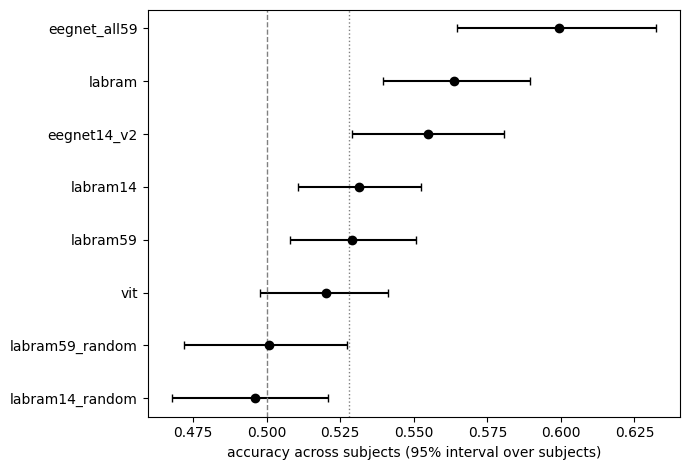

In [9]:
import matplotlib.pyplot as plt
order = sorted(NAMES, key=lambda t: ACC[t])
fig, ax = plt.subplots(figsize=(7, 0.45 * len(order) + 1.2))
for i, t in enumerate(order):
    ax.errorbar(ACC[t], i, xerr=[[ACC[t] - RES[t]["ci"][0]], [RES[t]["ci"][1] - ACC[t]]], fmt="o", color="black", capsize=3)
ax.axvline(0.5, color="gray", ls="--", lw=1); ax.axvline(0.528, color="gray", ls=":", lw=1)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlabel("accuracy across subjects (95% interval over subjects)")
plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/accuracy_by_model.png", dpi=200); plt.show()

## 10. Save progress back to GitHub

In [10]:
!git add notebooks/11_evaluate_all_models.ipynb
!git commit -m "All models evaluated from many directions: intervals, permutation test, leave-one-subject-out, calibration, identity, pairwise tests"
!git pull --rebase
!git push

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
